# Шаг 6. Мини-GPT учится писать «как Пушкин»

Соберём всё вместе в **маленький трансформер** (класс `MiniGPT` в `common.py`) и научим его угадывать следующий символ «Евгения Онегина».

**Архитектура `MiniGPT`:**

| Часть | Что делает |
|-------|------------|
| `token_emb` — Embedding символов (шаг 3) | номер символа → вектор из 128 чисел: «что за символ» |
| `pos_emb` — Embedding позиций | номер места 0…63 → вектор: «где стоит символ» (вниманию самому порядок неизвестен — шаг 5, пункт 7) |
| 4 × `Block` | **внимание** (шаг 5, 4 головы): посмотреть на предыдущие символы; **MLP**: «подумать» над тем, что увидел. `x + ...` — остаточная связь |
| `head` — Linear | вектор → оценки для каждого из 75 символов словаря |

Обучение — тот же цикл, что в сессиях 3–4: случайные куски текста по 64 символа, loss = cross-entropy, оптимизатор Adam.
Внутри одного куска модель учится сразу 64 раза: угадать 2-й символ по 1-му, 3-й по первым двум, … 65-й по 64 предыдущим.

**Структура примера (алгоритм):**
1. Переводим текст в номера, последние 10% откладываем для проверки.
2. Учимся нарезать случайные куски `x` и сдвинутые на один символ `y`.
3. Создаём модель (~800 тысяч весов), смотрим, где эти веса, и проводим через неё один батч.
4. Обучаем 3000 шагов; каждые 250 шагов печатаем loss и то, что модель пишет сейчас.
5. Сохраняем модель в `gpt.pt`, историю — в `gpt.json`, рисуем кривые.
6. Заглядываем внутрь: какие символы модель ждёт следующими и куда смотрят головы внимания.
7. Просим модель продолжить свои строки при разной температуре.
8. Проверяем, пишет ли модель своё или списывает из романа.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session05")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

## Общий модуль `common.py`

Во всех примерах сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `load_names()`, `load_text()` | русские имена из `names.txt` и «Евгений Онегин» (главы 1–8) из `onegin.txt` |
| `CharTokenizer(text)` | словарь символов: `encode` — строка → номера, `decode` — номера → строка, `vocab_size` — размер словаря |
| `name_tokenizer`, `bigram_pairs`, `bigram_counts` | словарь для имён (точка `.` — начало/конец имени), пары «буква → следующая», таблица подсчётов |
| `sample_name(probs, tok)` | придумать имя по таблице вероятностей |
| `apply_temperature(logits, T)` | вероятности из «сырых оценок» с температурой T |
| `MiniGPT`, `Block`, `SelfAttention` | маленький трансформер по символам |
| `save_gpt`, `load_gpt` | сохранить / загрузить GPT вместе со словарём |
| `load_session04()` | модуль `common.py` из сессии 4 (кошки и собаки, `SimpleCNN`) — для бонуса |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session05`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. Тексты лежат в этой же папке, интернет не нужен.

## 1. Данные: текст → номера, куски x и y

`y` — это `x`, сдвинутый на один символ: для каждого символа `x` правильный ответ — следующий символ.

Проверочный текст — это **конец** романа, а не случайные куски: иначе соседние куски из обучения и проверки
перекрывались бы, и модель «видела» бы проверку заранее.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import torch

from common import CharTokenizer, MiniGPT, count_params, load_text, save_gpt, show

torch.manual_seed(0)
text = load_text()
tok = CharTokenizer(text)
data = torch.tensor(tok.encode(text))
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]          # последние 10% текста модель не видит при обучении
print(f"Символов: {len(data)}, для обучения {len(train_data)}, для проверки {len(val_data)}")

BLOCK = 64          # сколько символов модель видит за раз
BATCH = 32          # сколько кусков текста в одном шаге обучения
STEPS = 3000        # шагов обучения (на обычном ноутбуке — несколько минут)


def get_batch(source):
    """Случайные куски текста x и те же куски, сдвинутые на один символ вперёд, y."""
    starts = torch.randint(len(source) - BLOCK - 1, (BATCH,))
    x = torch.stack([source[s:s + BLOCK] for s in starts])
    y = torch.stack([source[s + 1:s + BLOCK + 1] for s in starts])
    return x, y


x, y = get_batch(train_data)
print("Пример входа: ", repr(tok.decode(x[0][:30])))
print("Что угадывать:", repr(tok.decode(y[0][:30])))

Символов: 138204, для обучения 124383, для проверки 13821
Пример входа:  'райней мере\nТак думал он, и бы'
Что угадывать: 'айней мере\nТак думал он, и был'


## 2. Модель

Больше всего весов — в блоках (внимание и MLP). Эмбеддинги и `head` маленькие, потому что словарь всего из 75 символов.
У больших моделей со словарём BPE на 100 000 токенов эмбеддинги — заметная часть всех весов (вспомните шаг 1).

**Путь батча через модель.** Форма тензоров меняется так:
- номера `(32, 64)` → эмбеддинги символов + мест `(32, 64, 128)`;
- 4 блока не меняют форму, только содержимое: каждый символ «узнаёт» про своих соседей слева;
- `head` даёт `(32, 64, 75)` — по 75 оценок для **каждой** из 64 позиций каждого куска.

**Проверка перед обучением.** Новая модель ничего не знает, и её loss должен быть близок к угадыванию наугад — `log(75) ≈ 4.3`.
Если вышло намного больше — в модели ошибка. Это полезная привычка: проверять loss до первого шага.

In [2]:
model = MiniGPT(tok.vocab_size, block_size=BLOCK)
print("Весов в модели:", count_params(model))
for part in ["token_emb", "pos_emb", "blocks", "head"]:
    print(f"  {part:>9}: {count_params(getattr(model, part)):7d}")

# Путь одного батча через модель (dropout выключен, чтобы не тратить случайные числа)
model.eval()
with torch.no_grad():
    emb = model.token_emb(x) + model.pos_emb(torch.arange(BLOCK))
    print("Вход x:", tuple(x.shape), "= (кусков, символов в куске)")
    print("Эмбеддинги символов + мест:", tuple(emb.shape), "= (кусков, символов, чисел на символ)")
    print("После 4 блоков:", tuple(model.blocks(emb).shape), "— форма та же, меняется содержание")
    logits, loss = model(x, y)
    print("Оценки следующего символа:", tuple(logits.shape), f"= (кусков, символов, {tok.vocab_size} вариантов)")
model.train()
print(f"Loss до обучения: {loss:.3f}, угадывание наугад: log({tok.vocab_size}) = {math.log(tok.vocab_size):.3f}")

Весов в модели: 820811
  token_emb:    9600
    pos_emb:    8192
     blocks:  793088
       head:    9675
Вход x: (32, 64) = (кусков, символов в куске)
Эмбеддинги символов + мест: (32, 64, 128) = (кусков, символов, чисел на символ)
После 4 блоков: (32, 64, 128) — форма та же, меняется содержание
Оценки следующего символа: (32, 64, 75) = (кусков, символов, 75 вариантов)
Loss до обучения: 4.434, угадывание наугад: log(75) = 4.317


## 3. Обучение

Около 3–6 минут на обычном ноутбуке. Следите за образцами текста:
1. Сначала — случайные символы.
2. Через несколько сотен шагов — пробелы и переводы строк на месте, «слова» нужной длины.
3. Потом — настоящие слова, заглавная буква в начале строки, запятые в конце, строки длиной со стихотворную.

Смысла у текста не будет: модель крошечная и прочитала всего одну книгу. Но **форма** стиха выучивается удивительно быстро.

`model.eval()` / `model.train()` переключают dropout: при проверке и генерации он выключен, при обучении — включён.

In [3]:
@torch.no_grad()
def estimate_loss(iters=20):
    """Средний loss на обучающем и проверочном тексте."""
    model.eval()
    result = {}
    for name, source in [("train", train_data), ("val", val_data)]:
        result[name] = torch.stack([model(*get_batch(source))[1] for _ in range(iters)]).mean().item()
    model.train()
    return result


def sample(prompt="\n", n_new=200, temperature=0.8, seed=0):
    """Дописать текст к началу prompt."""
    g = torch.Generator().manual_seed(seed)
    idx = torch.tensor([tok.encode(prompt)])
    out = tok.decode(model.generate(idx, n_new, temperature, g)[0])
    model.train()
    return out


history = {"step": [], "train": [], "val": [], "samples": []}
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
start = time.time()
for step in range(STEPS + 1):
    if step % 250 == 0:
        losses = estimate_loss()
        text_now = sample("Мой дядя", n_new=120)
        for key in ("train", "val"):
            history[key].append(losses[key])
        history["step"].append(step)
        history["samples"].append(text_now)
        print(f"\nШаг {step:4d} ({time.time() - start:4.0f} с): loss обуч. {losses['train']:.3f}, проверка {losses['val']:.3f}")
        print(text_now)
    if step == STEPS:
        break
    x, y = get_batch(train_data)
    _, loss = model(x, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


Шаг    0 (   1 с): loss обуч. 4.461, проверка 4.461
Мой дядясмЕФЧфигсМуо.бОТРуПсВО?УцбеЭзЮчажг-Зю,!У)эЧЛыЧнчРРпЬгбЭЧ——фЗОгбы«Гц:ШДа:ТшбгъТ)взЭоТх)йжЛСХцгфОякЯгйхвйкыжг—чЬЭЮу,ИяХ.ёУ

Шаг  250 (  23 с): loss обуч. 2.479, проверка 2.474
Мой дядясь
Он посму браскуда Оноцом
И сажи м жавы овылнена
Добылиноетсты денолаль,
За длицо хой пот, огднегд,
Рамнять, сумая лен

Шаг  500 (  46 с): loss обуч. 2.253, проверка 2.245
Мой дядясь он послуд.
Они да Онец крушит печна!
Ни вы не спленогосте стыливенье.
Чтоло вором и женным,
Все дов кон е слазмая лен

Шаг  750 (  68 с): loss обуч. 2.081, проверка 2.119
Мой дядясь он послушит
Ты дальноцом вамажным жалых вы,
И спладною сердцы двествет,
Ило во о холжать горяк,
Но полняться умая люб

Шаг 1000 (  93 с): loss обуч. 1.966, проверка 2.027
Мой дядясь он послух..
Ты дам но берез аж ем ж!
— Что не спленною себя,
К веслать быловли он делей
Забыла из в коняет, сумая..
У

Шаг 1250 ( 118 с): loss обуч. 1.859, проверка 1.970
Мой дядя моей послух.
Он уж не болету

## 4. Кривые обучения

Если loss на проверочном тексте перестаёт падать, а на обучающем продолжает — это **переобучение**, как в сессии 4:
модель начинает заучивать «Онегина» наизусть. Обычно лучший loss на проверке (~1.9) получается около шагов 2000–2250,
дальше он растёт, а на обучающем тексте продолжает падать до ~1.3. Бороться можно так же: dropout, меньше модель, больше данных
или просто остановиться вовремя.

Для сравнения: угадывание наугад из 75 символов даёт loss `log(75) ≈ 4.3` — с него обучение и начинается.

Модель сохранена в gpt.pt


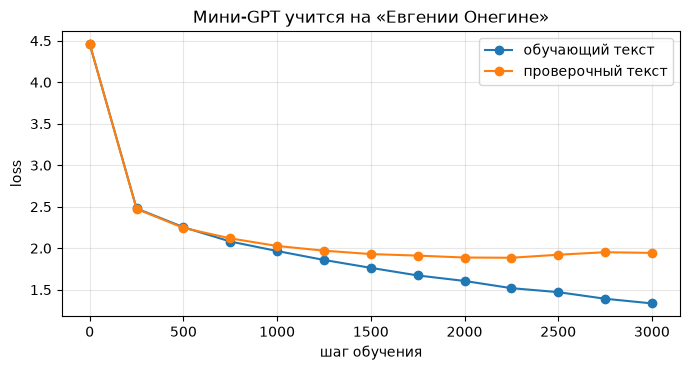

In [4]:
save_gpt(model, tok, "gpt", history)

plt.figure(figsize=(7, 3.8))
plt.plot(history["step"], history["train"], "o-", label="обучающий текст")
plt.plot(history["step"], history["val"], "o-", label="проверочный текст")
plt.xlabel("шаг обучения")
plt.ylabel("loss")
plt.title("Мини-GPT учится на «Евгении Онегине»")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("gpt_curves.png", dpi=100)
show()

## 5. Что модель думает о следующем символе

Генерация — это много раз подряд «угадай следующий символ». Посмотрим на одно такое угадывание:
пять самых вероятных символов и их вероятности (`↵` — перевод строки).

- После «Онеги» модель уверена в «н» почти на 100%: имя героя встречается в романе сотни раз.
- После «прави» чаще всего ставит на «л» (как в первой строке), но допускает и «т», «д» — «правит», «правда» тоже бывают.
- После «правил,↵» начинается новая строка стиха — модель ставит на заглавные буквы, чаще всего «И».
- После «Евгений» — перевод строки, запятая или пробел: модель знает, что имя часто стоит в конце строки.
- Где вариантов много, вероятности размазаны — именно тут температура решает, каким выйдет текст.

In [5]:
def visible(s):
    """Строка с видимым переводом строки (↵) — чтобы его было видно при печати."""
    return s.replace("\n", "↵")


@torch.no_grad()
def next_char(prompt, k=5):
    """k самых вероятных следующих символов после prompt по мнению модели."""
    model.eval()
    logits, _ = model(torch.tensor([tok.encode(prompt)]))
    model.train()
    p, idx = torch.softmax(logits[0, -1], dim=0).topk(k)
    return ", ".join(f"«{visible(tok.itos[i])}» {pi:.2f}" for pi, i in zip(p.tolist(), idx.tolist()))


print("Что модель думает о следующем символе:")
for prompt in ["Мой дядя самых честных прави", "Онеги", "Татьян", "Мой дядя самых честных правил,\n", "Евгений"]:
    print(f"  «{visible(prompt)}» → {next_char(prompt)}")

Что модель думает о следующем символе:
  «Мой дядя самых честных прави» → «л» 0.42, «т» 0.21, «д» 0.19, «н» 0.06, «,» 0.02
  «Онеги» → «н» 0.99, «б» 0.00, «е» 0.00, « » 0.00, «,» 0.00
  «Татьян» → «а» 0.77, «у» 0.14, «е» 0.04, «ы» 0.04, «о» 0.01
  «Мой дядя самых честных правил,↵» → «И» 0.26, «К» 0.11, «О» 0.08, «П» 0.07, «С» 0.07
  «Евгений» → «↵» 0.36, «,» 0.28, « » 0.24, «!» 0.04, «.» 0.03


## 6. Куда смотрят головы

Это уже не придуманные вручную веса из шага 5, а то, что модель выучила сама. Каждая картинка — одна голова последнего блока;
строка — символ, который сейчас «читает» модель, столбец — на какой из предыдущих символов он смотрит.

У разных голов разные «привычки»: одни смотрят в основном на ближайшие символы (яркая полоса у диагонали),
другие — на пробелы и начала слов или далеко назад. Никто модель этому не учил — так оказалось удобнее угадывать следующий символ.
Расшифровать, что именно делает каждая голова, непросто даже для учёных: этим занимается целая наука — интерпретируемость.

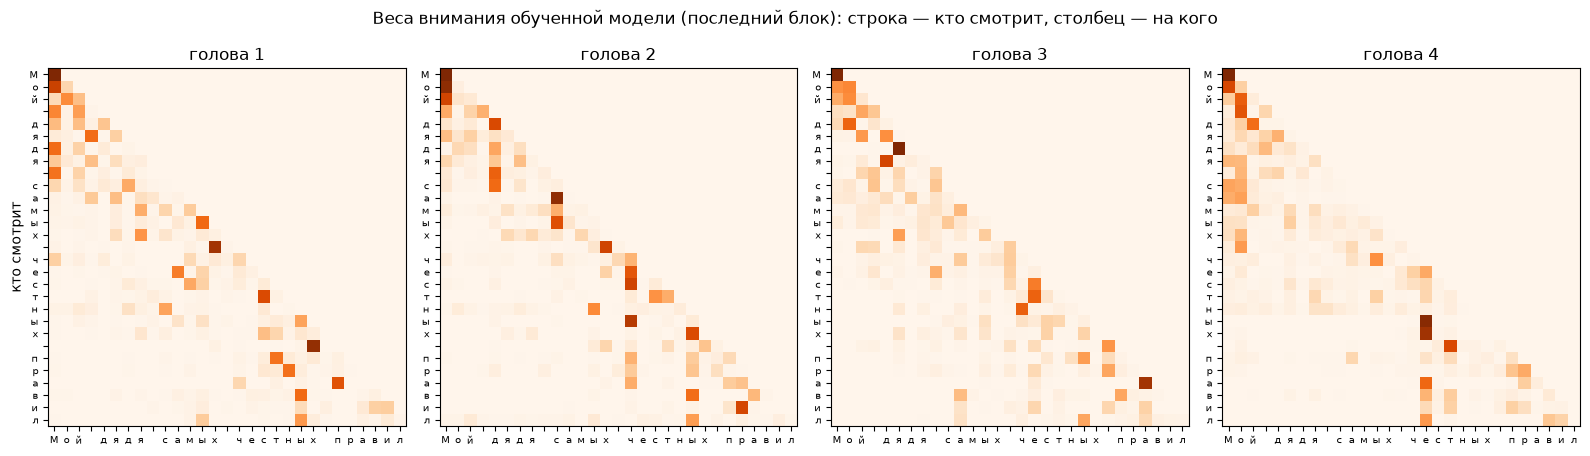

In [6]:
# Куда смотрят головы внимания последнего блока, когда модель читает строку
line = "Мой дядя самых честных правил"
model.eval()
with torch.no_grad():
    model(torch.tensor([tok.encode(line)]))
model.train()
weights = model.blocks[-1].attn.last_weights[0]          # (головы, символы, символы)
fig, axes = plt.subplots(1, weights.shape[0], figsize=(16, 4.6))
for h, ax in enumerate(axes):
    ax.imshow(weights[h], cmap="Oranges", vmin=0, vmax=1)
    ax.set_xticks(range(len(line)), list(line), fontsize=7)
    ax.set_yticks(range(len(line)), list(line), fontsize=7)
    ax.set_title(f"голова {h + 1}")
axes[0].set_ylabel("кто смотрит")
fig.suptitle("Веса внимания обученной модели (последний блок): строка — кто смотрит, столбец — на кого")
plt.tight_layout()
plt.savefig("gpt_attention.png", dpi=100)
show()

## 7. Допиши за Пушкина

Даём начало строки — модель продолжает. Сравните температуры: 0.5 — аккуратнее, но с повторами; 1.0 — живее, но больше выдуманных слов.

In [7]:
print("\n=== Допиши за Пушкина ===")
for prompt in ["Онегин, добрый мой приятель,\n", "Татьяна", "Зима!"]:
    for t in [0.5, 1.0]:
        print(f"\n--- «{prompt.strip()}», температура {t}:")
        print(sample(prompt, n_new=250, temperature=t, seed=1))


=== Допиши за Пушкина ===

--- «Онегин, добрый мой приятель,», температура 0.5:
Онегин, добрый мой приятель,
В которой услух и след.

И высоковать в наши старины.

И странный лорнет и брегет
И приятный друг других затей.

В ним привездный красногов страха,
И странный старой без гремя
Перед ним на ваше светлений
И наслажденный страстей.

Она под ней своей пр

--- «Онегин, добрый мой приятель,», температура 1.0:
Онегин, добрый мой приятель,
В кесну смулоких в досеным
Друг обморотник с окамьких дум,
Иль горловиц она должна;
Принятся Май старина знал.

Богинь, галову сердце женать?
Как он, как саду сказать.
Ногда вечное тусь».

Так мыслите поламе
Кипомно на билую деревне
Господь назяделяе

--- «Татьяна», температура 0.5:
Татьяна, краснув на видном
И забыть, на долго прикрачно
На старый имеет младой день
Ребят явленялся их страх.

И начался б не приняла слава
Поет вечера собою
Пора воспою душою странной
Предучка и в верной душе моей
Кипут о на балконец. Через и сталью,
Смель

--- «Татьяна»

## 8. Своё или списанное?

Модель прочитала роман много раз — может, она просто пересказывает его наизусть? Проверим:
найдём в сгенерированном тексте самый длинный кусок, который **дословно** есть в «Онегине».

Обычно это 10–15 символов: частые слова и обрывки фраз. Целые строки модель не копирует — она складывает текст
из выученных кусочков заново. Если учить модель намного дольше, она начнёт заучивать роман (вспомните переобучение из пункта 4) — и кусочки станут длиннее.
У больших моделей такая проверка — серьёзная задача: модель не должна дословно выдавать тексты, на которых училась.

In [8]:
def longest_copy(generated):
    """Самый длинный кусок generated, который дословно есть в «Онегине»."""
    best = ""
    for i in range(len(generated)):
        while i + len(best) < len(generated) and generated[i:i + len(best) + 1] in text:
            best = generated[i:i + len(best) + 1]
    return best


# Пишет ли модель своё или списывает? Ищем самый длинный дословный кусок из романа
for t in [0.5, 1.0]:
    generated = sample("\n", n_new=500, temperature=t, seed=2)
    copy = longest_copy(generated)
    print(f"\nТемпература {t}: самый длинный кусок из «Онегина» — {len(copy)} символов: «{visible(copy)}»")


Температура 0.5: самый длинный кусок из «Онегина» — 13 символов: «им.↵↵Татьяна »

Температура 1.0: самый длинный кусок из «Онегина» — 11 символов: « поэтически»


## Попробуйте сами

1. Напишите своё начало строки в `sample("...")` и `next_char("...")`. Работают ли незнакомые модели символы? (Подсказка: словарь — шаг 1.)
2. Поменяйте `n_layer` или `n_embd` в `MiniGPT(...)`: модель в 2 раза меньше/больше. Как изменились loss и время?
3. Уменьшите `BLOCK` до 8. Чем стал хуже текст? Почему? (Сравните с биграммой — у неё «блок» всего 1.)
4. Нарисуйте веса внимания первого блока (`model.blocks[0]`) вместо последнего. Чем они отличаются?
5. Обучите модель на своём тексте: другой книге, песнях, коде на Python. Достаточно заменить `onegin.txt`.
6. Большие модели вроде ChatGPT устроены так же, только у них токены BPE, десятки тысяч токенов в словаре,
   сотни блоков, миллиарды весов и тексты почти всего интернета.